# 16 — Cycled Assimilation on Lorenz-63

Every analysis so far was a single window with a background handed to
us. Operational assimilation is a *cycle*: forecast from the last
analysis, receive new observations, analyse, forecast again, forever.
The background is never given — it is yesterday's analysis pushed
through the model, and its error is whatever the chaos of the system
made of yesterday's analysis error. This notebook runs that loop on
Lorenz-63 with the [`pipekit_cycle`](https://jejjohnson.github.io/vardax/reference/cycle/) orchestration,
for a single-time analysis every step and for a 4DVar analysis over
windows of several steps, and looks at the two questions a cycle
raises that a single window cannot: how the error settles to an
equilibrium, and how badly things go when the background covariance is
wrong.

## The Bayesian recursion and its Gaussian approximation

With state-space model $x_k = M(x_{k-1})$ and observations
$y_k = H x_k + \varepsilon_k$, the filtering posterior obeys

$$
p(x_k \mid y_{1:k}) \;\propto\; p(y_k \mid x_k)\int p(x_k \mid x_{k-1})\,p(x_{k-1} \mid y_{1:k-1})\,dx_{k-1},
$$

a *forecast* step that pushes the previous posterior through the
dynamics, followed by an *analysis* step that multiplies by the
likelihood. For a linear model and Gaussian errors this is the Kalman
filter: the forecast covariance is $P^f_k = M' P^a_{k-1} M'^{\top}$
(plus model error), the analysis is the BLUE of chapter
[4](../04_oi_blue.md) with $B = P^f_k$, and the analysis covariance is
$P^a_k = (I - K_k H) P^f_k$.

Cycled 3DVar (or OI, the two coincide for linear $H$) is the Kalman
filter with one simplification: it does not propagate covariances. The
background covariance is a **fixed** $B$, chosen once, standing in for
the flow-dependent $P^f_k$ it cannot afford to compute. That
simplification is the whole story of this notebook's failures and
fixes. With too small a $B$ the analysis trusts its forecast too much,
stops listening to the observations, and *diverges*: the error grows
with the dynamics while the filter reports confidence. With too large
a $B$ it overfits each observation and the analysis inherits the
observation noise. Somewhere in between, $B$ matches the actual
forecast-error variance and the cycle is as good as a static $B$ can
make it.

## An equilibrium argument

How good is that? A scalar caricature says most of it. Let the
analysis error variance be $e_a^2$; between analyses the chaotic
dynamics amplify it to a forecast error $e_f^2 = e_a^2\, e^{2\lambda\Delta t}$,
with $\lambda$ the leading Lyapunov exponent and $\Delta t$ the cycle
length. A well-tuned analysis then combines forecast and observation by
precision, $1/e_a^2 = 1/e_f^2 + 1/\sigma_o^2$. At steady state the two
relations close:

$$
e_a^2 = \sigma_o^2\,\big(1 - e^{-2\lambda\Delta t}\big), \qquad
e_f^2 = \sigma_o^2\,\big(e^{2\lambda\Delta t} - 1\big).
$$

The analysis error is a fixed fraction of the observation error, set
only by how many Lyapunov times pass between observations; observe
often relative to $1/\lambda$ and the cycle beats the instrument by a
wide margin. The second relation is the value of $B$ a static filter
should use: the forecast error the cycle itself produces. For
Lorenz-63 ($\lambda \approx 0.9$) observed every $\Delta t = 0.1$ it
predicts $e_a \approx 0.41\,\sigma_o$ and $\sigma_b \approx 0.44\,\sigma_o$.
The scalar model ignores that Lorenz-63's error growth is neither
uniform in time nor isotropic in state, so we will treat these as
order-of-magnitude guides and let the experiment say the rest.

## Diagnosing $B$ from the innovations

The cycle also tells you whether $B$ is right, without knowing the
truth. The innovation $d_k = y_k - H x^f_k$ has, if the error models
hold, covariance $H B H^{\top} + R$; comparing the measured innovation
variance with $\sigma_b^2 + \sigma_o^2$ is the classic consistency
check (Desroziers et al. 2005 extend it to separate $B$ from $R$). We
compute it for every run below.

## Windows: cycled 4DVar

Instead of an analysis at every observation time, a strong-constraint
4DVar can take a window of $W$ observation times, use the forecast at
the window's first time as background, and analyse the whole window at
once — a fixed-lag smoother with a static $B$ at the window start.
The state at the window's end is the carrier for the next window. The
dynamics inside the window are exact, so the observations after the
first time constrain the initial state through the tangent-linear
model, and the effective covariance the analysis uses is
flow-dependent within the window even though $B$ is static at its
start. That is the operational reason 4DVar outperforms 3DVar at the
same observation count, and the experiment reproduces it.

## Where the pieces live

[`pipekit_cycle.DACycle`](https://jejjohnson.github.io/vardax/reference/cycle/) runs forecast–observe–analyse
for a given number of steps; `SmootherCycle` collects a window of
forecasts and observations and calls the analysis once per window.
vardax models plug in through the `AnalysisStep` protocol via
`.as_analysis_step()`, and the [`VarDACycle`](xref:api#vardax.VarDACycle) factory
wires that up. The adapters shipped with the models hold their
background fixed, which is right for a one-off analysis; a cycle needs
the background to *be the forecast*, so below we write two small
analysis steps that rebuild the vardax model around the forecast on
every call. That is a dozen lines each, and it is the pattern for any
cycled use of a vardax model.

In [1]:
import diffrax as dfx
import equinox as eqx
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import numpy as np
import pipekit
import pipekit_cycle as pc

from vardax import (
    Batch1D,
    DynTrajectory,
    Lorenz63,
    MaskedIdentity,
    OptimalInterpolation,
    SoftBoundedForward,
    StrongFourDVar,
    simulate_lorenz63,
)

## 1. Truth, observations, and the forward model

Three hundred cycles of $\Delta t = 0.1$ (thirty time units, about
twenty-seven Lyapunov times), all three components observed at every
cycle with $\sigma_o = 1$. The truth comes from the same Lorenz-63
flow the cycle uses, so the only errors are in the initial state and
the observations; model error is notebook
[12](12_weak_constraint_4dvar_L63.ipynb)'s subject.

In [2]:
DT, N_CYCLES = 0.1, 300
SIGMA_OBS = 1.0
LAMBDA = 0.9  # leading Lyapunov exponent of Lorenz-63

ode = DynTrajectory(model=Lorenz63(sigma=10.0, rho=28.0, beta=8.0 / 3.0), adjoint=dfx.DirectAdjoint())
forward = SoftBoundedForward(ode.as_forward_model(dt=DT), bound=60.0)

_, x_spin = simulate_lorenz63(jax.random.PRNGKey(0), dt=0.01, n_steps=500, n_burn_in=1000)
ts = jnp.arange(N_CYCLES + 1) * DT
x_true = ode(x_spin[-1], ts)  # x_true[k] is the truth after k cycles
k_obs, k_init = jax.random.split(jax.random.PRNGKey(1))
y_obs = x_true[1:] + SIGMA_OBS * jax.random.normal(k_obs, (N_CYCLES, 3))  # y_obs[k] observes x_true[k + 1]
x_init = x_true[0] + 3.0 * jax.random.normal(k_init, (3,))  # a poor initial state to spin up from

obs_source = pipekit.Lambda(lambda k: y_obs[k], name="obs")


def diag_cov(variance):
    return lx.TaggedLinearOperator(lx.DiagonalLinearOperator(jnp.full(3, variance)), lx.positive_semidefinite_tag)


def rmse(x, ref):
    return jnp.sqrt(jnp.mean((x - ref) ** 2, axis=-1))

## 2. An analysis step whose background is the forecast

`pipekit_cycle` calls the analysis step as
`step(forecast, obs, obs_op=..., obs_err_cov=...)`. Ours builds an
`OptimalInterpolation` around the forecast with a static $B = \sigma_b^2 I$
and returns its analysis; the solve is jitted with the forecast as an
argument, so the model is rebuilt inside the trace and compiled once.

cycle state after the run: t = 30.0, cycles = 300
time-mean RMSE after spin-up (50 cycles): free run 9.84, forecast 0.56, analysis 0.55, observations 1.00
scalar equilibrium guide: analysis 0.41, forecast 0.44


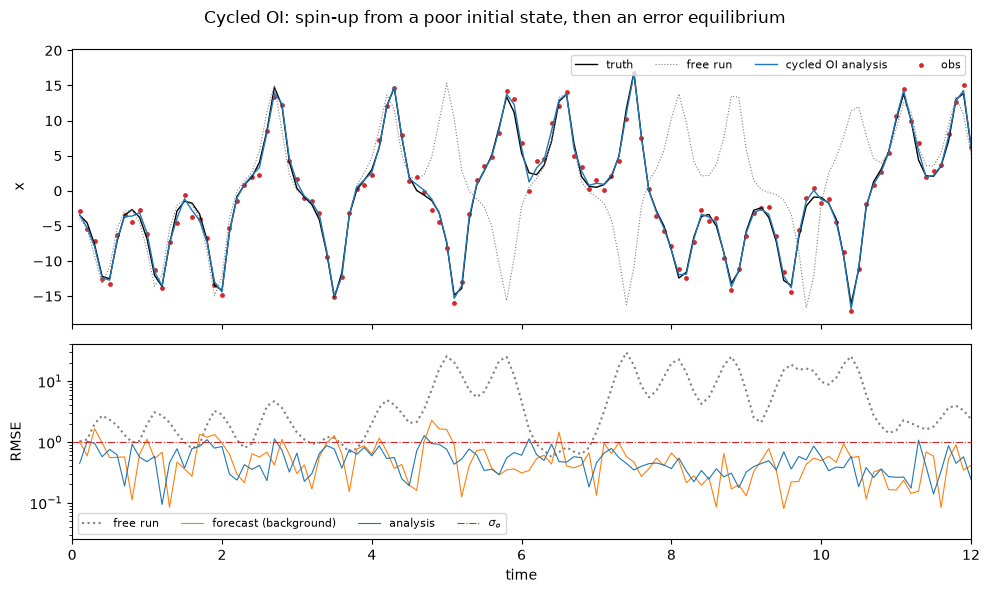

In [3]:
class ForecastBackgroundOI(eqx.Module):
    """AnalysisStep: OI with the forecast as background and B = sigma_b^2 I."""

    sigma_b: float

    def __call__(self, forecast, obs, *, obs_op, obs_err_cov):
        return _oi_analysis(forecast, obs, self.sigma_b)


@jax.jit
def _oi_analysis(forecast, obs, sigma_b):
    oi = OptimalInterpolation(
        obs_op=MaskedIdentity(), prior_mean=forecast,
        prior_cov_op=diag_cov(sigma_b**2), obs_cov_op=diag_cov(SIGMA_OBS**2),
    )
    return oi(Batch1D(input=obs[None], mask=jnp.ones((1, 3))))[0]


def run_cycle(step, n_steps=N_CYCLES):
    cycle = pc.DACycle(forward_model=forward, obs_op=MaskedIdentity(), analysis_step=step,
                       obs_source=obs_source, n_steps=n_steps, save_history=True)
    x_end, state = cycle(x_init, pc.DAState(t=0.0, cycle_count=0, obs_err_cov=SIGMA_OBS**2 * jnp.eye(3)))
    forecasts = jnp.stack([f for f, _ in cycle.history])
    analyses = jnp.stack([a for _, a in cycle.history])
    return forecasts, analyses, state


assert isinstance(ForecastBackgroundOI(sigma_b=1.0), pc.AnalysisStep)

SIGMA_B = 1.0  # the optimum of the sweep in section 3
forecasts_oi, analyses_oi, state = run_cycle(ForecastBackgroundOI(sigma_b=SIGMA_B))
free_run = ode(x_init, ts)[1:]
print(f"cycle state after the run: t = {state.t:.1f}, cycles = {state.cycle_count}")

err_free = rmse(free_run, x_true[1:])
err_fc = rmse(forecasts_oi, x_true[1:])
err_an = rmse(analyses_oi, x_true[1:])
SPINUP = 50
print(f"time-mean RMSE after spin-up ({SPINUP} cycles): free run {float(err_free[SPINUP:].mean()):.2f}, "
      f"forecast {float(err_fc[SPINUP:].mean()):.2f}, analysis {float(err_an[SPINUP:].mean()):.2f}, "
      f"observations {SIGMA_OBS:.2f}")
print(f"scalar equilibrium guide: analysis {SIGMA_OBS * np.sqrt(1 - np.exp(-2 * LAMBDA * DT)):.2f}, "
      f"forecast {SIGMA_OBS * np.sqrt(np.exp(2 * LAMBDA * DT) - 1):.2f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[1.4, 1])
axes[0].plot(ts[1:], x_true[1:, 0], color="black", lw=1, label="truth")
axes[0].plot(ts[1:], free_run[:, 0], color="gray", lw=0.8, linestyle=":", label="free run")
axes[0].plot(ts[1:], analyses_oi[:, 0], color="tab:blue", lw=1, label="cycled OI analysis")
axes[0].scatter(ts[1:], y_obs[:, 0], color="tab:red", s=6, label="obs")
axes[0].set_xlim(0, 12)
axes[0].set_ylabel("x")
axes[0].legend(ncol=4, fontsize=8, loc="upper right")
axes[1].plot(ts[1:], err_free, color="gray", linestyle=":", label="free run")
axes[1].plot(ts[1:], err_fc, color="tab:orange", lw=0.8, label="forecast (background)")
axes[1].plot(ts[1:], err_an, color="tab:blue", lw=0.8, label="analysis")
axes[1].axhline(SIGMA_OBS, color="tab:red", linestyle="-.", lw=0.8, label=r"$\sigma_o$")
axes[1].set_yscale("log")
axes[1].set_ylabel("RMSE")
axes[1].set_xlabel("time")
axes[1].legend(ncol=4, fontsize=8)
fig.suptitle("Cycled OI: spin-up from a poor initial state, then an error equilibrium")
plt.tight_layout()
plt.show()

The free run loses the truth within a couple of Lyapunov times; the
cycle spins up from the same poor start in a few cycles and then
hovers around an equilibrium well below the observation noise. The
forecast error sits above the analysis error by the growth factor of
one cycle, and both spike when the trajectory passes near the saddle
between the two lobes, where the local growth rate is far above the
global Lyapunov exponent — the scalar model's blind spot.

## 3. Tuning $B$: divergence, overfitting, and the innovation check

The same run for a range of $\sigma_b$, keeping everything else fixed.
Alongside the true error (which we can only compute because this is a
twin experiment) we record the innovation variance, which an
operational system *can* compute, and compare it with the value
$\sigma_b^2 + \sigma_o^2$ the filter assumes.

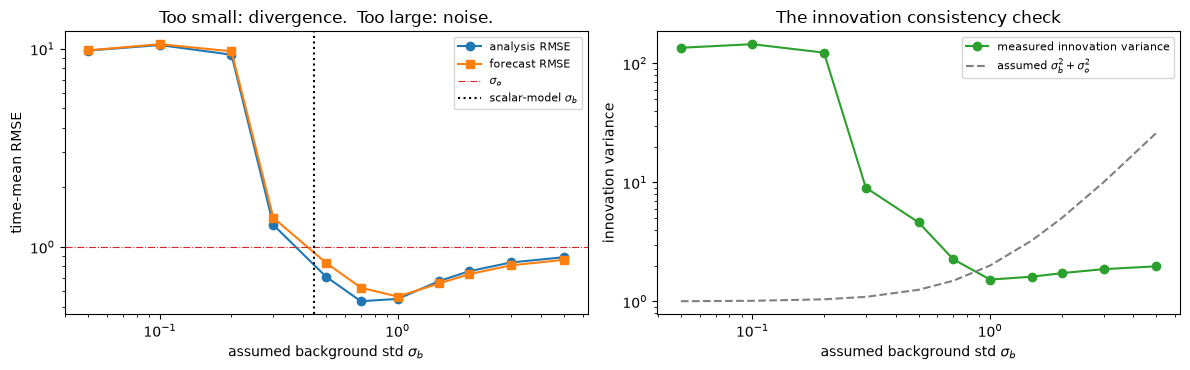

best sigma_b in the sweep: 0.70 (analysis RMSE 0.53); innovation variance there 2.26 vs assumed 1.49


In [4]:
sigma_b_grid = np.array([0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0])
sweep_an, sweep_fc, sweep_innov = [], [], []
for sb in sigma_b_grid:
    fc, an, _ = run_cycle(ForecastBackgroundOI(sigma_b=float(sb)))
    sweep_an.append(float(rmse(an, x_true[1:])[SPINUP:].mean()))
    sweep_fc.append(float(rmse(fc, x_true[1:])[SPINUP:].mean()))
    sweep_innov.append(float(jnp.mean((y_obs[SPINUP:] - fc[SPINUP:]) ** 2)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].loglog(sigma_b_grid, sweep_an, marker="o", color="tab:blue", label="analysis RMSE")
axes[0].loglog(sigma_b_grid, sweep_fc, marker="s", color="tab:orange", label="forecast RMSE")
axes[0].axhline(SIGMA_OBS, color="tab:red", linestyle="-.", lw=0.8, label=r"$\sigma_o$")
axes[0].axvline(SIGMA_OBS * np.sqrt(np.exp(2 * LAMBDA * DT) - 1), color="black", linestyle=":", label="scalar-model $\\sigma_b$")
axes[0].set_xlabel(r"assumed background std $\sigma_b$")
axes[0].set_ylabel("time-mean RMSE")
axes[0].legend(fontsize=8)
axes[0].set_title("Too small: divergence.  Too large: noise.")
axes[1].loglog(sigma_b_grid, sweep_innov, marker="o", color="tab:green", label="measured innovation variance")
axes[1].loglog(sigma_b_grid, sigma_b_grid**2 + SIGMA_OBS**2, color="gray", linestyle="--", label=r"assumed $\sigma_b^2 + \sigma_o^2$")
axes[1].set_xlabel(r"assumed background std $\sigma_b$")
axes[1].set_ylabel("innovation variance")
axes[1].legend(fontsize=8)
axes[1].set_title("The innovation consistency check")
plt.tight_layout()
plt.show()

best = int(np.argmin(sweep_an))
print(f"best sigma_b in the sweep: {sigma_b_grid[best]:.2f} (analysis RMSE {sweep_an[best]:.2f}); "
      f"innovation variance there {sweep_innov[best]:.2f} vs assumed {sigma_b_grid[best]**2 + SIGMA_OBS**2:.2f}")

Left: with $\sigma_b$ well below the actual forecast error the cycle
diverges — the analysis error climbs toward the free-run level even
though observations arrive every step, because each one is given
almost no weight. With $\sigma_b$ too large the analysis becomes the
observation and its error approaches $\sigma_o$. The minimum sits where
$\sigma_b$ is close to the forecast error the cycle actually produces,
about twice the scalar model's guess: the real growth is intermittent,
and a static $B$ has to cover the bursts near the saddle as well as the
quiet stretches on the lobes.

Right: on the divergent side the measured innovation variance is two
orders of magnitude above the assumed $\sigma_b^2 + \sigma_o^2$ — the
forecast is nowhere near the data, and the data say so. As $\sigma_b$
grows the measured variance falls to a floor set by the actual forecast
error plus $\sigma_o^2$, while the assumed curve rises; they cross
near the optimum, where the filter is consistent with its own
innovations. That crossing is computable without a truth, which is how
an operational system tunes $B$ and detects divergence.

## 4. Cycled 4DVar over windows

Now a window of $W = 5$ observation times. The analysis step receives
the window's forecasts and observations, takes the first forecast as
the background, minimises the strong-constraint cost over the window
with [`StrongFourDVar`](xref:api#vardax.StrongFourDVar), and returns the analysed
state at the window's end as the carrier for the next window. Both
cycles see exactly the same observations; only the grouping differs.

time-mean analysis RMSE after spin-up, sigma_b = 1.0: cycled OI 0.55, cycled 4DVar (W = 5) 0.27
best over the sigma_b sweep: cycled OI 0.53, cycled 4DVar 0.20


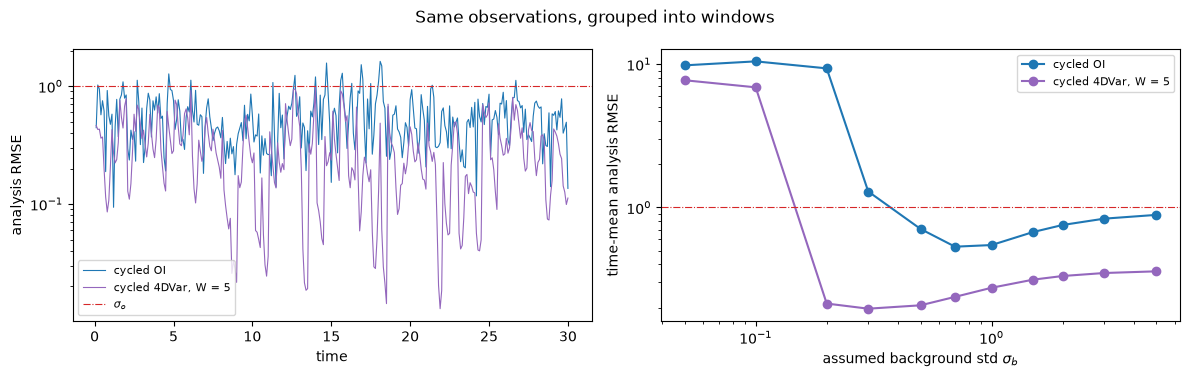

In [5]:
W = 5


class WindowFourDVar(eqx.Module):
    """AnalysisStep for SmootherCycle: strong 4DVar over the window, forecast[0] as background."""

    sigma_b: float
    trace: list = eqx.field(static=True, default_factory=list)  # analysed windows, for scoring

    def __call__(self, forecasts, observations, *, obs_op, obs_err_cov):
        x_b = forecasts[0]
        y = jnp.stack(observations)
        traj = _window_analysis(x_b, y, self.sigma_b)
        self.trace.append(traj)
        return traj[-1]


@jax.jit
def _window_analysis(x_b, y, sigma_b):
    strong = StrongFourDVar(
        forward=forward, obs_op=MaskedIdentity(), prior_mean=x_b,
        prior_cov_op=diag_cov(sigma_b**2), obs_cov_op=diag_cov(SIGMA_OBS**2), max_steps=200,
    )
    x0 = strong(Batch1D(input=y[None], mask=jnp.ones((1, W, 3))))[0]

    def step(x, _):
        x_new = forward.step(x, DT)
        return x_new, x_new

    _, rest = jax.lax.scan(step, x0, None, length=W - 1)
    return jnp.concatenate([x0[None], rest], axis=0)


def run_windows(sigma_b):
    step = WindowFourDVar(sigma_b=sigma_b, trace=[])
    # In pipekit_cycle, ``stride`` is the number of consecutive windows one call
    # processes (each ``window`` steps long, back to back), not a step offset:
    # N_CYCLES // W windows of W steps cover all N_CYCLES observation times.
    smoother = pc.SmootherCycle(forward_model=forward, obs_op=MaskedIdentity(), analysis_step=step,
                                window=W, stride=N_CYCLES // W, obs_source=obs_source)
    smoother(x_init, pc.DAState(t=0.0, cycle_count=0, obs_err_cov=SIGMA_OBS**2 * jnp.eye(3)))
    return jnp.concatenate(step.trace, axis=0)  # (N_CYCLES, 3): analysed state at every obs time


analyses_4d = run_windows(SIGMA_B)
err_4d = rmse(analyses_4d, x_true[1:])
sweep_4d = []
for sb in sigma_b_grid:
    sweep_4d.append(float(rmse(run_windows(float(sb)), x_true[1:])[SPINUP:].mean()))

print(f"time-mean analysis RMSE after spin-up, sigma_b = {SIGMA_B}: cycled OI {float(err_an[SPINUP:].mean()):.2f}, "
      f"cycled 4DVar (W = {W}) {float(err_4d[SPINUP:].mean()):.2f}")
print(f"best over the sigma_b sweep: cycled OI {min(sweep_an):.2f}, cycled 4DVar {min(sweep_4d):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ts[1:], err_an, color="tab:blue", lw=0.8, label="cycled OI")
axes[0].plot(ts[1:], err_4d, color="tab:purple", lw=0.8, label=f"cycled 4DVar, W = {W}")
axes[0].axhline(SIGMA_OBS, color="tab:red", linestyle="-.", lw=0.8, label=r"$\sigma_o$")
axes[0].set_yscale("log")
axes[0].set_xlabel("time")
axes[0].set_ylabel("analysis RMSE")
axes[0].legend(fontsize=8)
axes[1].loglog(sigma_b_grid, sweep_an, marker="o", color="tab:blue", label="cycled OI")
axes[1].loglog(sigma_b_grid, sweep_4d, marker="o", color="tab:purple", label=f"cycled 4DVar, W = {W}")
axes[1].axhline(SIGMA_OBS, color="tab:red", linestyle="-.", lw=0.8)
axes[1].set_xlabel(r"assumed background std $\sigma_b$")
axes[1].set_ylabel("time-mean analysis RMSE")
axes[1].legend(fontsize=8)
fig.suptitle("Same observations, grouped into windows")
plt.tight_layout()
plt.show()

The windowed cycle is more accurate at every $\sigma_b$, and markedly
less sensitive to it: within a window the observations after the first
time constrain the state through the dynamics, so the analysis depends
less on the static $B$ that only enters at the window start. It is
also more robust on the divergent side, for the same reason — five
observations pulling through the tangent-linear model are harder to
ignore than one. The cost is that the analysis at the window's first
time is only available after the window's last observation: a
smoother's latency, and the reason operational systems combine
windowed analyses with short-cycle updates.

## Summary

- A cycle is the Bayesian filtering recursion; cycled 3DVar/OI is the
  Kalman filter with a frozen background covariance.
- The analysis error settles to an equilibrium set by the observation
  error and by how many Lyapunov times pass between observations; a
  scalar balance predicts it to within a factor of two, the rest being
  the intermittency of the flow.
- $B$ too small diverges, $B$ too large overfits; the innovation
  variance, computable without a truth, tells which side you are on.
- Grouping the same observations into 4DVar windows lowers the error
  and the sensitivity to $B$, because the dynamics inside the window
  supply the flow-dependence a static $B$ lacks.

The forward model here was exact. With a biased model the equilibrium
argument acquires a model-error term that does not shrink with more
observations — chapter [7](../07_weak_4dvar.md) and notebook
[12](12_weak_constraint_4dvar_L63.ipynb) — and with a learned forward
model the cycle is where the closures of notebook
[13](13_neural_closure_L96.ipynb) earn their keep.